# EXP-11 – Decision Tree: Classification Threshold (V2)

## 1. Mục tiêu thí nghiệm

Thí nghiệm EXP-11 V2 tiếp tục khảo sát ảnh hưởng của ngưỡng phân loại (Classification Threshold) đến hiệu quả dự đoán của thuật toán Decision Tree trên bộ dữ liệu Bank Marketing. Cấu hình Decision Tree được giữ nhất quán với EXP-03 nhằm tập trung đánh giá tác động của việc lựa chọn ngưỡng phân loại.

Khác với V1, V2 sử dụng Pipeline kết hợp tiền xử lý và Decision Tree trong quá trình Stratified 5-Fold Cross-validation. Ngưỡng phân loại được lựa chọn từ xác suất dự đoán Out-of-Fold (OOF) trên tập huấn luyện theo tiêu chí F1-score. Sau đó, mô hình được huấn luyện trên toàn bộ tập train và ngưỡng được lựa chọn được áp dụng trên tập test.

Các chỉ số đánh giá gồm Accuracy, Precision, Recall, F1-score và ROC-AUC.

## 2. Phương pháp thực hiện – Phiên bản V2

Dữ liệu được chia thành tập huấn luyện và tập kiểm tra theo cùng tỷ lệ và `random_state` của các thí nghiệm trước. Các bước imputation, chuẩn hóa và One-Hot Encoding được đặt bên trong Pipeline. Trong mỗi fold, bộ tiền xử lý chỉ được fit trên phần dữ liệu huấn luyện của fold đó.

Threshold được khảo sát từ các giá trị xác suất OOF khác nhau được tạo ra bởi mô hình Cross-validation. Ngưỡng có F1-score OOF cao nhất được sử dụng để phân loại trên tập kiểm tra. Cấu hình Decision Tree được giữ nguyên so với EXP-03.

## 3. Thư viện và cấu hình đường dẫn

In [10]:
from pathlib import Path
from datetime import datetime
import sys
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.base import clone


def find_project_root():
    """Tìm thư mục gốc dự án từ thư mục làm việc hiện tại hoặc các thư mục cha."""
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (
            (candidate / "src" / "preprocessing.py").is_file()
            and (candidate / "data" / "raw" / "bank-additional-full.csv").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        "Không tìm thấy thư mục gốc dự án. Hãy đặt notebook trong "
        "notebooks/Decision_Tree hoặc mở Jupyter từ thư mục gốc dự án."
    )


ROOT_DIR = find_project_root()
RAW_DATA_PATH = ROOT_DIR / "data" / "raw" / "bank-additional-full.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print("Project root:", ROOT_DIR)
print("Raw data:", RAW_DATA_PATH)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)

Project root: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ
Raw data: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\data\raw\bank-additional-full.csv
Python: 3.15.0
Pandas: 3.1.0
Scikit-learn: 1.9.1


## 4. Đọc dữ liệu và chia tập train/test

Dữ liệu được đọc từ `data/raw/bank-additional-full.csv`. Các bản ghi trùng lặp và bản ghi thiếu nhãn được loại bỏ; biến mục tiêu `y` được mã hóa thành hai nhãn 0 và 1. Biến `duration` được loại khỏi tập đặc trưng.

Tập train và test được chia theo tỷ lệ 80:20, phân tầng theo nhãn và sử dụng `random_state=42` để bảo đảm cách chia nhất quán với các thí nghiệm trước.

In [11]:
df = pd.read_csv(RAW_DATA_PATH, sep=";")
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

if y.isna().any():
    invalid_labels = df_model.loc[y.isna(), "y"].unique().tolist()
    raise ValueError(f"Tồn tại nhãn mục tiêu chưa được ánh xạ: {invalid_labels}")

y = y.astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Toàn bộ dữ liệu sau làm sạch:", df_model.shape)
print("X_train_raw:", X_train_raw.shape)
print("X_test_raw:", X_test_raw.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Train class distribution:", y_train.value_counts().sort_index().to_dict())
print("Test class distribution:", y_test.value_counts().sort_index().to_dict())

display(pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index(),
}).rename(index={0: "no (0)", 1: "yes (1)"}).round(4))

Toàn bộ dữ liệu sau làm sạch: (41176, 21)
X_train_raw: (32940, 19)
X_test_raw: (8236, 19)
y_train: (32940,)
y_test: (8236,)
Train class distribution: {0: 29229, 1: 3711}
Test class distribution: {0: 7308, 1: 928}


,Train,Test
y,,
no (0),0.8873,0.8873
yes (1),0.1127,0.1127


### Nhận xét phân phối dữ liệu sau khi chia tập

Sau khi làm sạch, bộ dữ liệu còn **41.176 bản ghi và 21 cột**. Sau khi loại biến mục tiêu `y` và biến `duration`, tập đặc trưng còn 19 biến. Dữ liệu được chia thành 32.940 mẫu train và 8.236 mẫu test.

Tỷ lệ hai lớp được giữ đồng nhất ở cả hai tập: lớp `no (0)` chiếm **88,73%**, trong khi lớp `yes (1)` chiếm **11,27%**. Điều này cho thấy dữ liệu có sự mất cân bằng giữa hai lớp; vì vậy, việc đánh giá cần xem xét đồng thời Precision, Recall và F1-score, không chỉ dựa vào Accuracy.


## 5. Xây dựng Pipeline và tạo xác suất OOF

Pipeline gồm hai thành phần: bộ tiền xử lý dữ liệu và Decision Tree. Đặc trưng số được điền giá trị thiếu bằng median và chuẩn hóa bằng StandardScaler. Đặc trưng phân loại được điền giá trị thiếu bằng most_frequent và mã hóa One-Hot.

Pipeline được đưa trực tiếp vào Stratified 5-Fold Cross-validation. Vì vậy, trong mỗi fold, các bước tiền xử lý được fit từ phần train của fold và sau đó áp dụng lên phần validation tương ứng.

Với Stratified 5-Fold Cross-validation, tập train được chia thành 5 fold có tỷ lệ nhãn gần tương đương. Mỗi mẫu trong tập train lần lượt được dự đoán bởi mô hình không sử dụng mẫu đó để huấn luyện, từ đó tạo ra xác suất Out-of-Fold (OOF). Các xác suất OOF này được dùng để khảo sát threshold và lựa chọn ngưỡng theo F1-score trước khi đánh giá trên tập test.


In [12]:
numeric_features = X_train_raw.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train_raw.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
)

# Giữ nguyên cấu hình Decision Tree của EXP-03.
model_dt_template = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

pipeline_dt = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", model_dt_template),
])

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Mỗi mẫu trong X_train_raw nhận một xác suất dự đoán OOF.
oof_probability_matrix = cross_val_predict(
    clone(pipeline_dt),
    X_train_raw,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)

class_order = np.unique(y_train)
positive_class_index = int(np.where(class_order == 1)[0][0])
oof_probability = oof_probability_matrix[:, positive_class_index]

print("Số fold:", N_SPLITS)
print("Số xác suất OOF:", len(oof_probability))
print("Số mẫu train:", len(y_train))
print("Khoảng xác suất OOF:", (float(oof_probability.min()), float(oof_probability.max())))
assert len(oof_probability) == len(y_train)

Số fold: 5
Số xác suất OOF: 32940
Số mẫu train: 32940
Khoảng xác suất OOF: (0.0, 1.0)


## 6. Khảo sát và lựa chọn threshold bằng F1-score OOF

V2 sử dụng các giá trị threshold được tạo từ đường Precision-Recall của xác suất OOF thay vì quét một lưới cố định với bước nhảy 0,05. Với mỗi threshold, Precision, Recall và F1-score được tính trên tập huấn luyện OOF. Threshold có F1-score cao nhất được lựa chọn.

Số threshold được khảo sát: 426
Threshold được chọn: 0.64507200
OOF Precision: 0.4338
OOF Recall: 0.5484
OOF F1-score: 0.4844

20 threshold có F1-score cao nhất:


,Threshold,Precision,Recall,F1-score
0,0.645072,0.433809,0.548370,0.484408
1,0.645072,0.434979,0.546214,0.484291
2,0.649592,0.435616,0.545136,0.484261
3,0.663178,0.438045,0.541094,0.484147
4,0.645072,0.434326,0.546214,0.483886
5,0.663178,0.436336,0.542980,0.483852
6,0.611672,0.426689,0.558340,0.483717
7,0.588807,0.425702,0.559687,0.483586
8,0.718650,0.448411,0.524656,0.483547
9,0.657641,0.435195,0.543789,0.483469


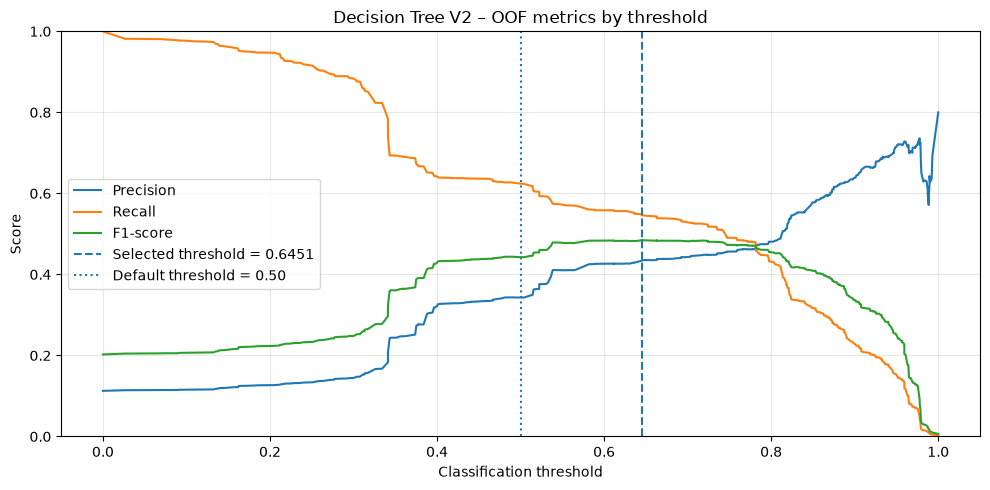

In [13]:
precision_values, recall_values, threshold_values = precision_recall_curve(
    y_train,
    oof_probability,
    pos_label=1,
)

# precision và recall có thêm một phần tử cuối; phần tử này không có threshold tương ứng.
precision_for_thresholds = precision_values[:-1]
recall_for_thresholds = recall_values[:-1]

f1_values = np.divide(
    2 * precision_for_thresholds * recall_for_thresholds,
    precision_for_thresholds + recall_for_thresholds,
    out=np.zeros_like(precision_for_thresholds),
    where=(precision_for_thresholds + recall_for_thresholds) != 0,
)

df_threshold = pd.DataFrame({
    "Threshold": threshold_values,
    "Precision": precision_for_thresholds,
    "Recall": recall_for_thresholds,
    "F1-score": f1_values,
})

if df_threshold.empty:
    raise RuntimeError("Không tạo được các giá trị threshold từ xác suất OOF.")

best_row_index = int(df_threshold["F1-score"].to_numpy().argmax())
best_threshold = float(df_threshold.iloc[best_row_index]["Threshold"])
best_oof_precision = float(df_threshold.iloc[best_row_index]["Precision"])
best_oof_recall = float(df_threshold.iloc[best_row_index]["Recall"])
best_oof_f1 = float(df_threshold.iloc[best_row_index]["F1-score"])

print("Số threshold được khảo sát:", len(df_threshold))
print(f"Threshold được chọn: {best_threshold:.8f}")
print(f"OOF Precision: {best_oof_precision:.4f}")
print(f"OOF Recall: {best_oof_recall:.4f}")
print(f"OOF F1-score: {best_oof_f1:.4f}")

print("\n20 threshold có F1-score cao nhất:")
display(
    df_threshold.sort_values(
        ["F1-score", "Threshold"],
        ascending=[False, True],
    ).head(20).reset_index(drop=True).round(6)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_threshold["Threshold"], df_threshold["Precision"], label="Precision")
ax.plot(df_threshold["Threshold"], df_threshold["Recall"], label="Recall")
ax.plot(df_threshold["Threshold"], df_threshold["F1-score"], label="F1-score")
ax.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.4f}")
ax.axvline(0.50, linestyle=":", label="Default threshold = 0.50")
ax.set_title("Decision Tree V2 – OOF metrics by threshold")
ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Nhận xét kết quả khảo sát threshold

Có **426 giá trị threshold** được khảo sát từ xác suất OOF. Ngưỡng đạt F1-score cao nhất là **0,645072**, với Precision **0,4338**, Recall **0,5484** và F1-score **0,4844**. Ngưỡng này được lựa chọn vì tạo ra F1-score OOF cao nhất trong các ngưỡng đã khảo sát.

Kết quả cho thấy khi threshold tăng, mô hình yêu cầu xác suất dự đoán cao hơn trước khi xếp một trường hợp vào lớp `yes`. Theo bảng khảo sát, Precision có xu hướng tăng, trong khi Recall giảm. Điều này thể hiện sự đánh đổi giữa việc hạn chế dự đoán dương tính sai và khả năng phát hiện các trường hợp thực sự thuộc lớp `yes`.

Trong 20 ngưỡng có F1-score cao nhất, các giá trị tập trung trong khoảng **0,4832–0,4844**. Chênh lệch F1-score giữa ngưỡng đứng đầu (0,484408) và ngưỡng xếp thứ hai (0,484291) là nhỏ. Do đó, threshold **0,645072** được giữ làm ngưỡng sử dụng cho lần đánh giá trên tập test.

Trên biểu đồ, đường nét đứt đánh dấu threshold được lựa chọn **0,645072**, nằm cao hơn đường chấm biểu thị threshold mặc định **0,50**. Các đường Precision, Recall và F1-score cho thấy sự thay đổi của ba chỉ số theo từng ngưỡng; vị trí 0,645072 tương ứng với F1-score OOF cao nhất trong lần khảo sát này.


## 7. Huấn luyện mô hình cuối cùng và đánh giá trên tập test

Sau khi lựa chọn threshold từ xác suất OOF trên tập train, Pipeline được huấn luyện lại trên toàn bộ tập train. Mô hình tạo xác suất trên tập test; các nhãn dự đoán được xác định theo ngưỡng mặc định của Decision Tree và threshold được lựa chọn ở phần 6.

In [14]:
def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "F1-score": float(f1_score(y_true, y_pred, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y_true, y_probability)),
    }


model_dt_v2 = clone(pipeline_dt)
model_dt_v2.fit(X_train_raw, y_train)

y_probability_test = model_dt_v2.predict_proba(X_test_raw)[:, positive_class_index]

# Mốc so sánh: nhãn do DecisionTreeClassifier.predict() trả về.
y_prediction_default = model_dt_v2.predict(X_test_raw)

# EXP-11 V2: áp dụng threshold tối ưu trên xác suất dự đoán.
y_prediction_threshold = (y_probability_test >= best_threshold).astype(int)

y_test_array = np.asarray(y_test).ravel()

baseline_v2_metrics = calculate_metrics(
    y_test_array,
    y_prediction_default,
    y_probability_test,
)

v2_metrics = calculate_metrics(
    y_test_array,
    y_prediction_threshold,
    y_probability_test,
)

print("Decision Tree V2 – threshold mặc định:")
display(pd.DataFrame([baseline_v2_metrics], index=["Default threshold"]).round(4))

print(f"EXP-11 V2 – threshold = {best_threshold:.8f}:")
display(pd.DataFrame([v2_metrics], index=["Decision Tree – EXP-11 V2"]).round(4))

Decision Tree V2 – threshold mặc định:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Default threshold,0.8263,0.353,0.6509,0.4577,0.7932


EXP-11 V2 – threshold = 0.64507200:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Decision Tree – EXP-11 V2,0.8764,0.4615,0.5808,0.5143,0.7932


### Nhận xét kết quả đánh giá trên tập test

Ở threshold mặc định, Decision Tree đạt Accuracy **0,8263**, Precision **0,3530**, Recall **0,6509**, F1-score **0,4577** và ROC-AUC **0,7932**. Khi áp dụng threshold **0,645072**, Accuracy tăng lên **0,8764**, Precision tăng lên **0,4615** và F1-score tăng lên **0,5143**. Recall giảm từ **0,6509** xuống **0,5808**, trong khi ROC-AUC giữ nguyên ở **0,7932**.

Như vậy, threshold được lựa chọn giúp cải thiện Precision và F1-score trên tập test, đồng thời làm giảm Recall. Kết quả thể hiện mô hình thận trọng hơn khi dự đoán lớp `yes`: tỷ lệ dự đoán dương tính đúng tăng lên, nhưng một phần trường hợp `yes` thực tế không được nhận diện.


## 8. Biểu đồ đánh giá

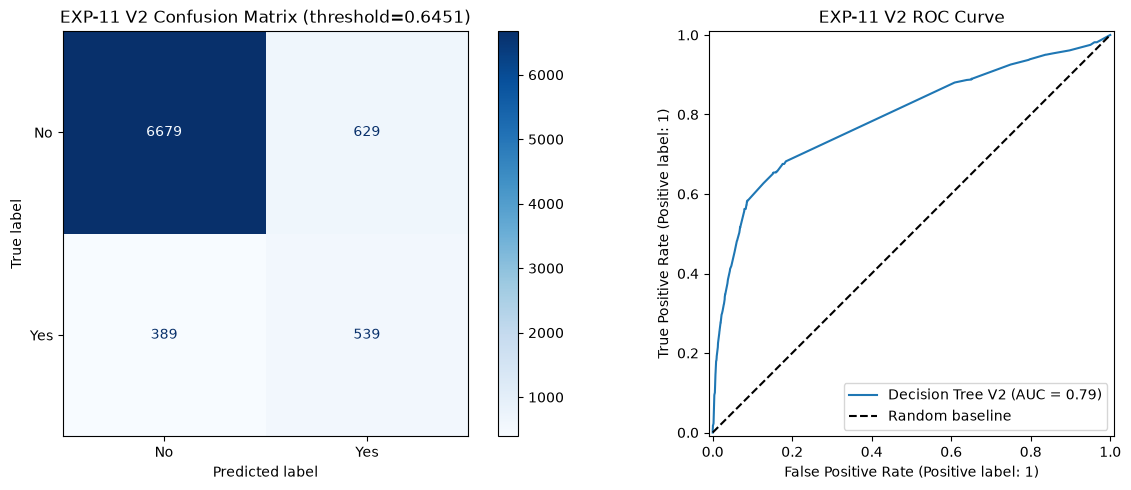

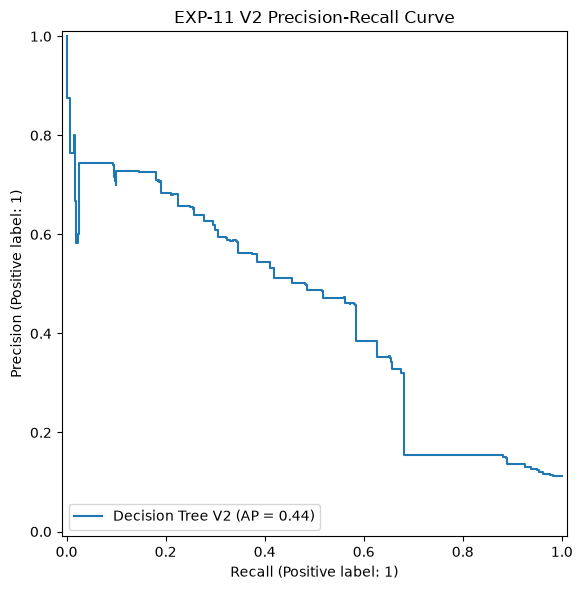

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_threshold,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title(f"EXP-11 V2 Confusion Matrix (threshold={best_threshold:.4f})")

RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V2",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("EXP-11 V2 ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V2",
    ax=ax,
)
ax.set_title("EXP-11 V2 Precision-Recall Curve")
plt.tight_layout()
plt.show()

### Nhận xét các biểu đồ đánh giá

**1. Confusion Matrix**

Với threshold 0,645072, ma trận nhầm lẫn trên tập test gồm **6.679 TN**, **629 FP**, **389 FN** và **539 TP**. Mô hình dự đoán đúng 6.679 trường hợp không đăng ký và nhận diện đúng 539 trường hợp có đăng ký. Tuy nhiên, vẫn còn 389 trường hợp `yes` bị dự đoán thành `no`.

So với threshold mặc định, số False Positive giảm từ **1.107 xuống 629**, trong khi False Negative tăng từ **324 lên 389**. Điều này phù hợp với sự thay đổi của Precision và Recall: mô hình giảm số trường hợp dự đoán nhầm khách hàng đăng ký, nhưng bỏ sót thêm một số khách hàng thực sự đăng ký.

**2. ROC Curve**

ROC-AUC đạt **0,7932**, cao hơn mức 0,5 của đường phân loại ngẫu nhiên. Kết quả cho thấy xác suất dự đoán của Decision Tree có khả năng phân biệt hai lớp. ROC-AUC không thay đổi so với threshold mặc định vì việc điều chỉnh threshold chỉ thay đổi cách chuyển xác suất thành nhãn dự đoán, không làm thay đổi các xác suất và thứ tự xếp hạng mẫu của mô hình.

**3. Precision-Recall Curve**

Lớp `yes` chiếm **11,27%** dữ liệu test, vì vậy Precision là chỉ số cần được xem xét cùng Recall trong bài toán này. Tại threshold được lựa chọn, Precision đạt **0,4615** và Recall đạt **0,5808**. Điều này có nghĩa 46,15% các trường hợp được mô hình dự đoán là `yes` thực sự thuộc lớp `yes`, đồng thời mô hình nhận diện được 58,08% tổng số trường hợp `yes` thực tế. Đường Precision-Recall thể hiện sự thay đổi giữa hai chỉ số này khi thay đổi ngưỡng phân loại.


## 9. Lưu kết quả thí nghiệm tự động

Mỗi lần chạy notebook tạo một thư mục kết quả riêng theo thời gian thực hiện. Các tệp lưu gồm cấu hình, chỉ số đánh giá, bảng threshold OOF, dự đoán trên tập test, mô hình Pipeline và biểu đồ.

In [16]:
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULTS_ROOT = ROOT_DIR / "notebooks" / "02_EDA" / "Experiments" / "Logs"
EXP11_V2_ROOT = RESULTS_ROOT / "Experiment_11_DecisionTree_threshold_V2"
RUN_DIR = EXP11_V2_ROOT / f"run_{RUN_ID}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

experiment_params = {
    "experiment": "EXP-11 Decision Tree Threshold V2",
    "model": "DecisionTreeClassifier",
    "model_parameters": model_dt_template.get_params(),
    "selected_threshold": best_threshold,
    "threshold_selection_metric": "OOF F1-score",
    "threshold_selection_method": "All unique thresholds from precision_recall_curve",
    "oof_precision_at_selected_threshold": best_oof_precision,
    "oof_recall_at_selected_threshold": best_oof_recall,
    "oof_f1_at_selected_threshold": best_oof_f1,
    "cross_validation": {
        "method": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE,
    },
    "train_test_split": {
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "stratify": True,
    },
    "preprocessing": {
        "numeric": ["SimpleImputer(median)", "StandardScaler"],
        "categorical": ["SimpleImputer(most_frequent)", "OneHotEncoder(handle_unknown=ignore)"],
        "inside_cross_validation_pipeline": True,
    },
}

with open(RUN_DIR / "params_cfg.json", "w", encoding="utf-8") as file:
    json.dump(experiment_params, file, ensure_ascii=False, indent=2, default=str)

with open(RUN_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(v2_metrics, file, ensure_ascii=False, indent=2)

pd.DataFrame([v2_metrics]).to_csv(RUN_DIR / "metrics.csv", index=False)
df_threshold.to_csv(RUN_DIR / "threshold_scan_oof.csv", index=False)

pd.DataFrame({
    "y_true": y_test_array,
    "y_pred_default": np.asarray(y_prediction_default).ravel(),
    "y_pred_threshold": np.asarray(y_prediction_threshold).ravel(),
    "y_probability_yes": np.asarray(y_probability_test).ravel(),
}).to_csv(RUN_DIR / "predictions.csv", index=False)

pd.DataFrame({
    "y_true": np.asarray(y_train).ravel(),
    "oof_probability_yes": np.asarray(oof_probability).ravel(),
}).to_csv(RUN_DIR / "oof_predictions.csv", index=False)

# Pipeline đã bao gồm preprocessor và Decision Tree; threshold được lưu riêng trong params_cfg.json.
joblib.dump(model_dt_v2, RUN_DIR / "best_model.pkl")
joblib.dump({
    "pipeline": model_dt_v2,
    "threshold": best_threshold,
    "positive_label": 1,
}, RUN_DIR / "model_bundle.pkl")

# Biểu đồ Confusion Matrix và ROC Curve.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_array,
    y_prediction_threshold,
    labels=[0, 1],
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0],
    values_format="d",
)
axes[0].set_title(f"Confusion Matrix (threshold={best_threshold:.4f})")
RocCurveDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V2",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")
plt.tight_layout()
fig.savefig(RUN_DIR / "confusion_roc.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# Biểu đồ thay đổi các chỉ số theo threshold OOF.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_threshold["Threshold"], df_threshold["Precision"], label="Precision")
ax.plot(df_threshold["Threshold"], df_threshold["Recall"], label="Recall")
ax.plot(df_threshold["Threshold"], df_threshold["F1-score"], label="F1-score")
ax.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.4f}")
ax.axvline(0.50, linestyle=":", label="Default = 0.50")
ax.set_title("OOF metrics by threshold – EXP-11 V2")
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "threshold_metrics_oof.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# Biểu đồ Precision-Recall trên tập test.
fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(
    y_test_array,
    y_probability_test,
    name="Decision Tree V2",
    ax=ax,
)
ax.set_title("Precision-Recall Curve – EXP-11 V2")
fig.tight_layout()
fig.savefig(RUN_DIR / "precision_recall_curve.png", dpi=150, bbox_inches="tight")
plt.close(fig)

print("EXP-11 V2 results saved to:", RUN_DIR)
print("Files created:")
for path in sorted(RUN_DIR.iterdir()):
    if path.is_file():
        print("-", path.name)

EXP-11 V2 results saved to: D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_11_DecisionTree_threshold_V2\run_20261126_221136_273175
Files created:
- best_model.pkl
- confusion_roc.png
- metrics.csv
- metrics.json
- model_bundle.pkl
- oof_predictions.csv
- params_cfg.json
- precision_recall_curve.png
- predictions.csv
- threshold_metrics_oof.png
- threshold_scan_oof.csv


## 10. So sánh EXP-03, EXP-11 V1 và EXP-11 V2

Các chỉ số EXP-03 và EXP-11 V1 được sử dụng làm kết quả tham chiếu từ những lần thực nghiệm trước. Kết quả EXP-11 V2 được lấy trực tiếp từ lần chạy hiện tại.

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,EXP-03 – Decision Tree Baseline,0.8263,0.3530,0.6509,0.4577,0.7932
1,EXP-11 V1 – Threshold 0.60,0.8757,0.4591,0.5808,0.5128,0.7932
2,EXP-11 V2 – Threshold 0.6451,0.8764,0.4615,0.5808,0.5143,0.7932


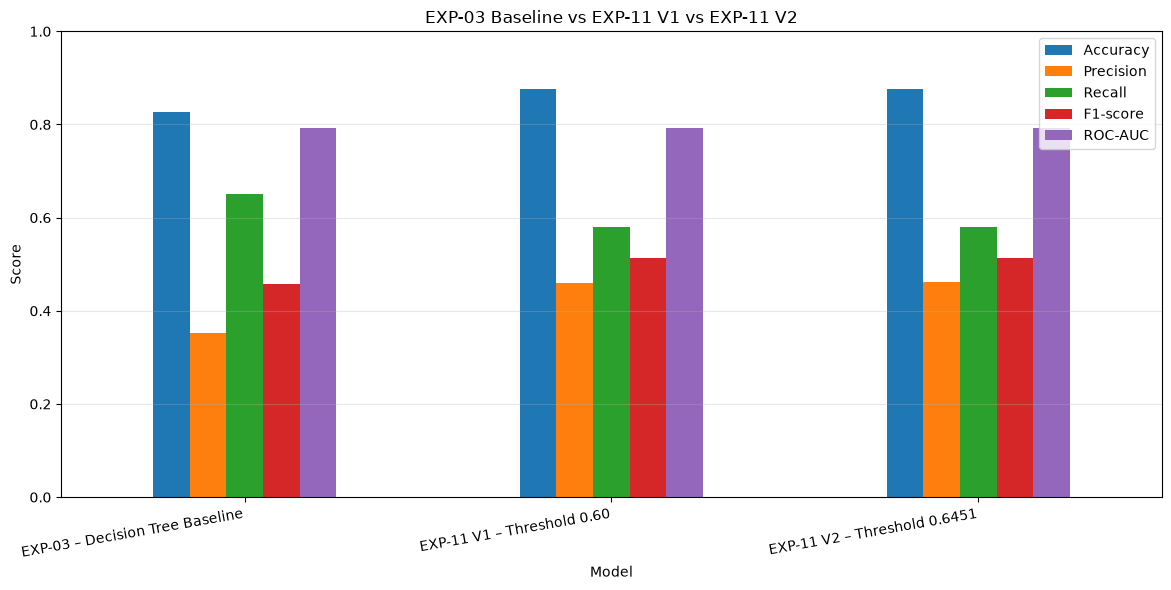

In [17]:
comparison_df = pd.DataFrame([
    {
        "Model": "EXP-03 – Decision Tree Baseline",
        "Accuracy": 0.8263,
        "Precision": 0.3530,
        "Recall": 0.6509,
        "F1-score": 0.4577,
        "ROC-AUC": 0.7932,
    },
    {
        "Model": "EXP-11 V1 – Threshold 0.60",
        "Accuracy": 0.8757,
        "Precision": 0.4591,
        "Recall": 0.5808,
        "F1-score": 0.5128,
        "ROC-AUC": 0.7932,
    },
    {
        "Model": f"EXP-11 V2 – Threshold {best_threshold:.4f}",
        **v2_metrics,
    },
])

display(comparison_df.round(4))
comparison_df.to_csv(RUN_DIR / "comparison_exp03_v1_v2.csv", index=False)

metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = comparison_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
)
ax.set_title("EXP-03 Baseline vs EXP-11 V1 vs EXP-11 V2")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()

### Nhận xét bảng và biểu đồ so sánh EXP-03, EXP-11 V1 và EXP-11 V2

So với EXP-03, EXP-11 V2 tăng Accuracy từ **0,8263 lên 0,8764**, Precision từ **0,3530 lên 0,4615** và F1-score từ **0,4577 lên 0,5143**. Mức thay đổi tương ứng là **+0,0501**, **+0,1085** và **+0,0566**. Recall giảm từ **0,6509 xuống 0,5808**, còn ROC-AUC giữ nguyên ở **0,7932**.

So với EXP-11 V1, EXP-11 V2 tiếp tục cải thiện nhẹ Accuracy từ **0,8757 lên 0,8764**, Precision từ **0,4591 lên 0,4615** và F1-score từ **0,5128 lên 0,5143**. Recall không thay đổi, cùng đạt **0,5808**, và ROC-AUC vẫn bằng **0,7932**.

Trên biểu đồ, EXP-11 V1 và V2 có các cột chỉ số khá gần nhau; V2 nhỉnh hơn V1 ở Accuracy, Precision và F1-score. Trong ba phiên bản được so sánh, EXP-11 V2 đạt F1-score cao nhất (**0,5143**). Kết quả cho thấy việc thay đổi cách lựa chọn threshold trong V2 mang lại mức cải thiện nhỏ so với V1, trong khi cả hai phiên bản đều cải thiện F1-score so với EXP-03.


## 11. Bảng kết quả tổng hợp

Kết quả EXP-11 V2 sử dụng threshold **0,645072**, được lựa chọn theo F1-score OOF **0,4844** trên tập train. Khi áp dụng trên tập test, mô hình đạt Accuracy **0,8764**, Precision **0,4615**, Recall **0,5808**, F1-score **0,5143** và ROC-AUC **0,7932**.

So với EXP-03, F1-score tăng từ **0,4577 lên 0,5143**. So với EXP-11 V1, F1-score tăng từ **0,5128 lên 0,5143**. Trong cả hai trường hợp, Precision được cải thiện nhưng Recall thấp hơn so với EXP-03.

Nhìn chung, EXP-11 V2 cho kết quả tốt nhất trong ba phiên bản xét theo F1-score. Việc lựa chọn threshold giúp cân bằng Precision và Recall theo tiêu chí F1-score, đồng thời quy trình Pipeline trong Cross-validation bảo đảm bước tiền xử lý được fit riêng trong từng fold.


In [18]:
print("Selected threshold:", best_threshold)
print("OOF F1-score:", best_oof_f1)
print("\nTest metrics:")
display(pd.DataFrame([v2_metrics], index=[f"EXP-11 V2 – threshold {best_threshold:.8f}"]).round(4))
print("\nOutput directory:")
print(RUN_DIR)

Selected threshold: 0.645072002648372
OOF F1-score: 0.48440847417281596

Test metrics:


,Accuracy,Precision,Recall,F1-score,ROC-AUC
EXP-11 V2 – threshold 0.64507200,0.8764,0.4615,0.5808,0.5143,0.7932



Output directory:
D:\#WS\Máy học\sgu2627k1_MayHoc\MayHoc_Nhom\Đồ án cuối kỳ\notebooks\02_EDA\Experiments\Logs\Experiment_11_DecisionTree_threshold_V2\run_20261126_221136_273175


## 12. Kết luận

EXP-11 V2 đã lựa chọn được threshold **0,645072** từ xác suất OOF bằng Stratified 5-Fold Cross-validation. Kết quả đánh giá trên tập test đạt F1-score **0,5143**, cao hơn EXP-03 (0,4577) và EXP-11 V1 (0,5128). Precision tăng, trong khi Recall giảm so với EXP-03; ROC-AUC giữ nguyên ở 0,7932.

Trong phạm vi thí nghiệm này, threshold 0,645072 cho kết quả F1-score tốt nhất trên tập OOF đã khảo sát và tạo ra kết quả F1-score cao nhất trong ba phiên bản trên tập test. Cấu hình Decision Tree được giữ nguyên, do đó sự khác biệt trong EXP-11 tập trung vào phương pháp lựa chọn và áp dụng threshold.
